# WaZP + DES-Y3 stacked-signal cross-check — plots only

Reads the pickles produced by `scripts/wazp_stacked_analysis.py` and
regenerates every plot from `notebooks/wazp_mass_richness_by_delta_m.ipynb`'s
methodology, applied to the same real WaZP + DES-Y3 catalogues used for the
joint (destacking) fit in `gamma_scan_outputs/run_2026-07-23T15-34-36`.

This notebook does **no** computation — no BallTree, no nested sampling, no
source catalogue loading. It only unpickles the script's five stage outputs
and plots them:

1. boost-factor diagnostic
2. stacked ΔΣ profiles
3. NFW + miscentering posterior corner (one example z/richness cell, low vs
   high Δm overlaid)
4. mass–richness data + per-Δm-group power-law fits
5. mass–richness (α, β, log M0) contour, low vs high Δm
6. mass–concentration data + per-Δm-group power-law fits, with theoretical
   c(M) overlays
7. mass–concentration (α, β, log c0) contour, low vs high Δm

Context: the joint per-cluster fit found `alpha_cm` incompatible with zero
on this data (see project memory `wazp-desy3-alpha-cm-anomaly`) — this
independent stacked pipeline is the cross-check.

In [1]:
import pickle

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import corner
from matplotlib.lines import Line2D

plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

In [2]:
# ── Load the five stage outputs ──────────────────────────────────────────
with open("../scripts/data/wazp_stacked_stacks.pkl", "rb") as f:
    _d = pickle.load(f)
radii     = _d["radii"]
z_edges   = _d["z_edges"]
ng_edges  = _d["ng_edges"]
stacks    = _d["stacks"]
N_NG      = len(ng_edges) - 1

with open("../scripts/data/wazp_stacked_fits.pkl", "rb") as f:
    fits_out = pickle.load(f)

with open("../scripts/data/wazp_stacked_ml_fits.pkl", "rb") as f:
    _ml = pickle.load(f)
LAM_PIV, Z_PIV, MIN_N_FOR_FIT = _ml["lam_piv"], _ml["z_piv"], _ml["min_n_for_fit"]
ml_fits = _ml["ml_fits"]

with open("../scripts/data/wazp_stacked_cmr_fits.pkl", "rb") as f:
    _cmr = pickle.load(f)
CMR_M_PIV, CMR_Z_PIV = _cmr["M_piv"], _cmr["z_piv"]
cmr_fits = _cmr["cmr_fits"]

PARAM_ORDER = ["log_M", "C", "FMISS", "SIGMA_OFF"]

n_ok = sum(1 for f in fits_out.values() if not f.get("failed"))
print(f"{len(stacks)} stacks, {n_ok}/{len(fits_out)} NFW fits converged")
print(f"M-lambda groups fitted: {sorted(ml_fits.keys())}")
print(f"c-M groups fitted: {sorted(cmr_fits.keys())}")

24 stacks, 24/24 NFW fits converged
M-lambda groups fitted: [0, 1]
c-M groups fitted: [0, 1]


## 1 — Boost-factor diagnostic

$B(R)$ for all stacks. Boost is already applied to `sigmas`/`sigmas_cov`
(see `stacked_signal applies the boost internally` — do not re-multiply).
Outer-bin boost should be near 1.

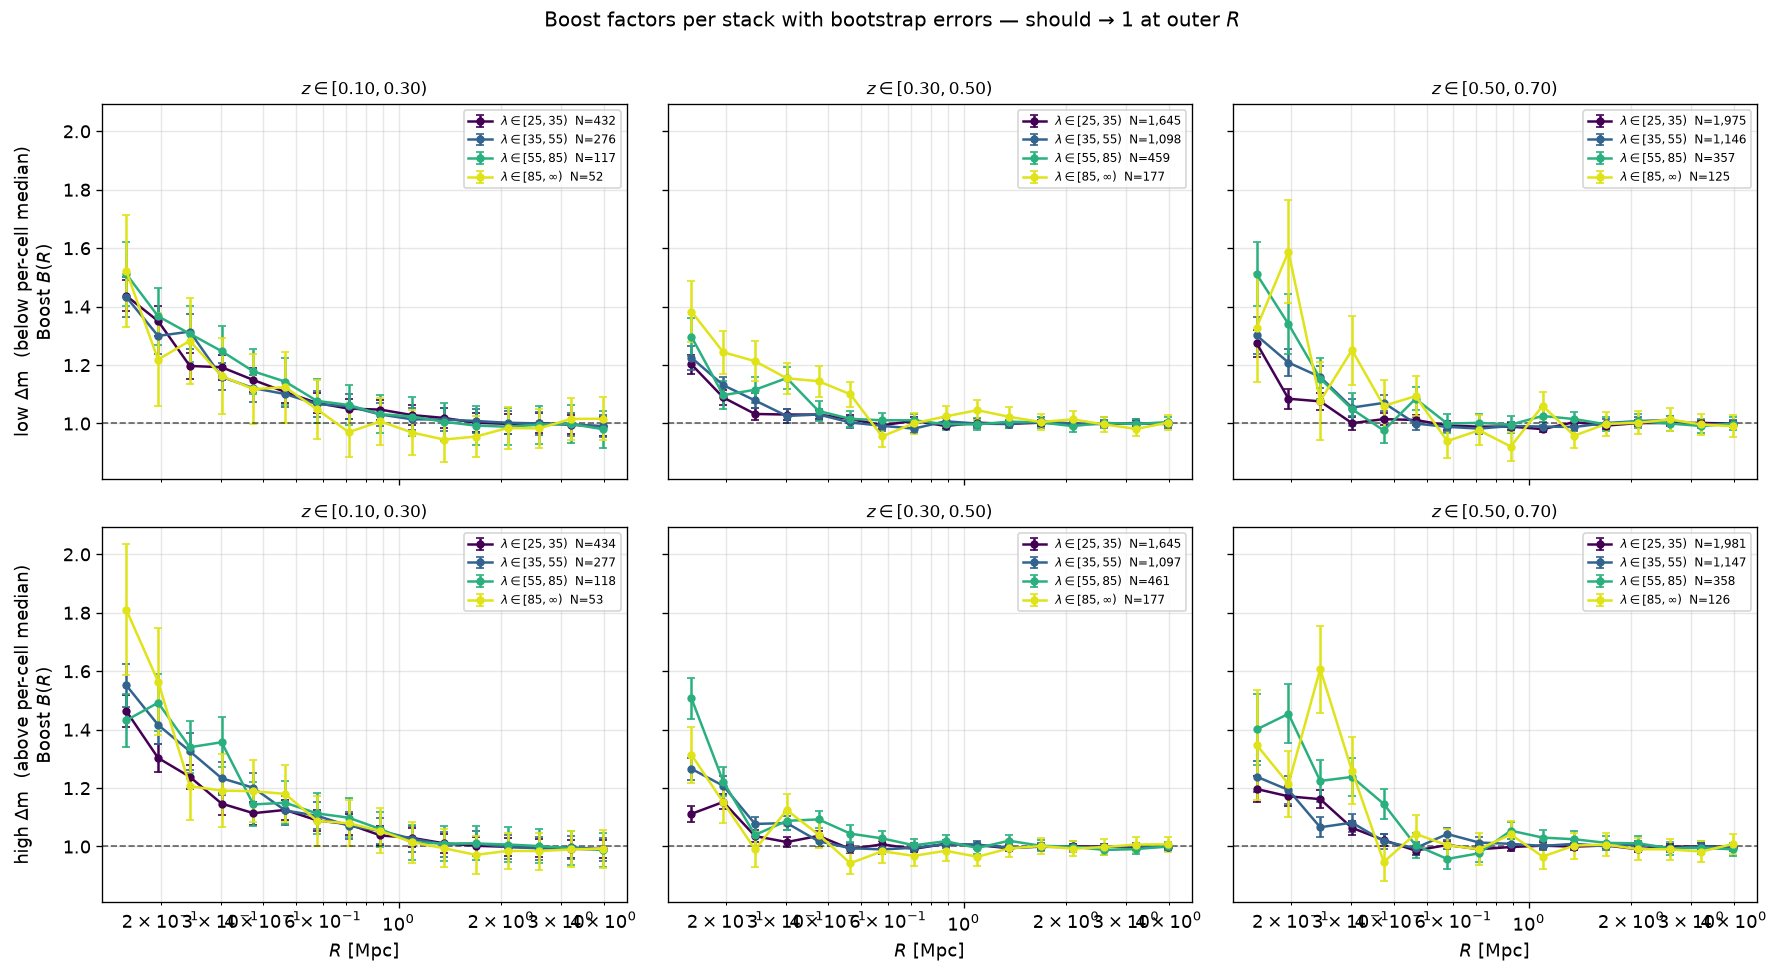

In [3]:
cmap = mpl.cm.viridis
ng_colors = [cmap(x) for x in np.linspace(0.0, 0.95, N_NG)]
dm_titles = {0: "low Δm  (below per-cell median)",
             1: "high Δm  (above per-cell median)"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for k in range(2):
    for i in range(3):
        ax = axes[k, i]
        for j in range(N_NG):
            name = f"z{i}_ng{j}_dm{k}"
            if name not in stacks:
                continue
            s = stacks[name]
            hi = f'{s["ng_hi"]:.0f}' if np.isfinite(s["ng_hi"]) else r"\infty"
            b_err = np.sqrt(np.diag(s["boosts_cov"]))
            ax.errorbar(radii, s["boosts"], yerr=b_err,
                        fmt="o-", ms=4, capsize=2.5, color=ng_colors[j],
                        label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                               f'N={s["n_stacked"]:,}'))
        ax.axhline(1.0, color="k", lw=1.0, ls="--", alpha=0.6)
        ax.set_xscale("log")
        if k == 1:
            ax.set_xlabel(r"$R$ [Mpc]")
        if i == 0:
            ax.set_ylabel(rf"{dm_titles[k]}" + "\n" + r"Boost $B(R)$")
        ax.set_title(rf"$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$", fontsize=10)
        ax.grid(alpha=0.3, which="both")
        ax.legend(fontsize=7, loc="upper right")

plt.suptitle("Boost factors per stack with bootstrap errors — should → 1 at outer $R$",
             fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 2 — Stacked profiles

Two rows (low-Δm vs high-Δm) × three columns (one per z slice), six NGALS
curves overlaid per panel.

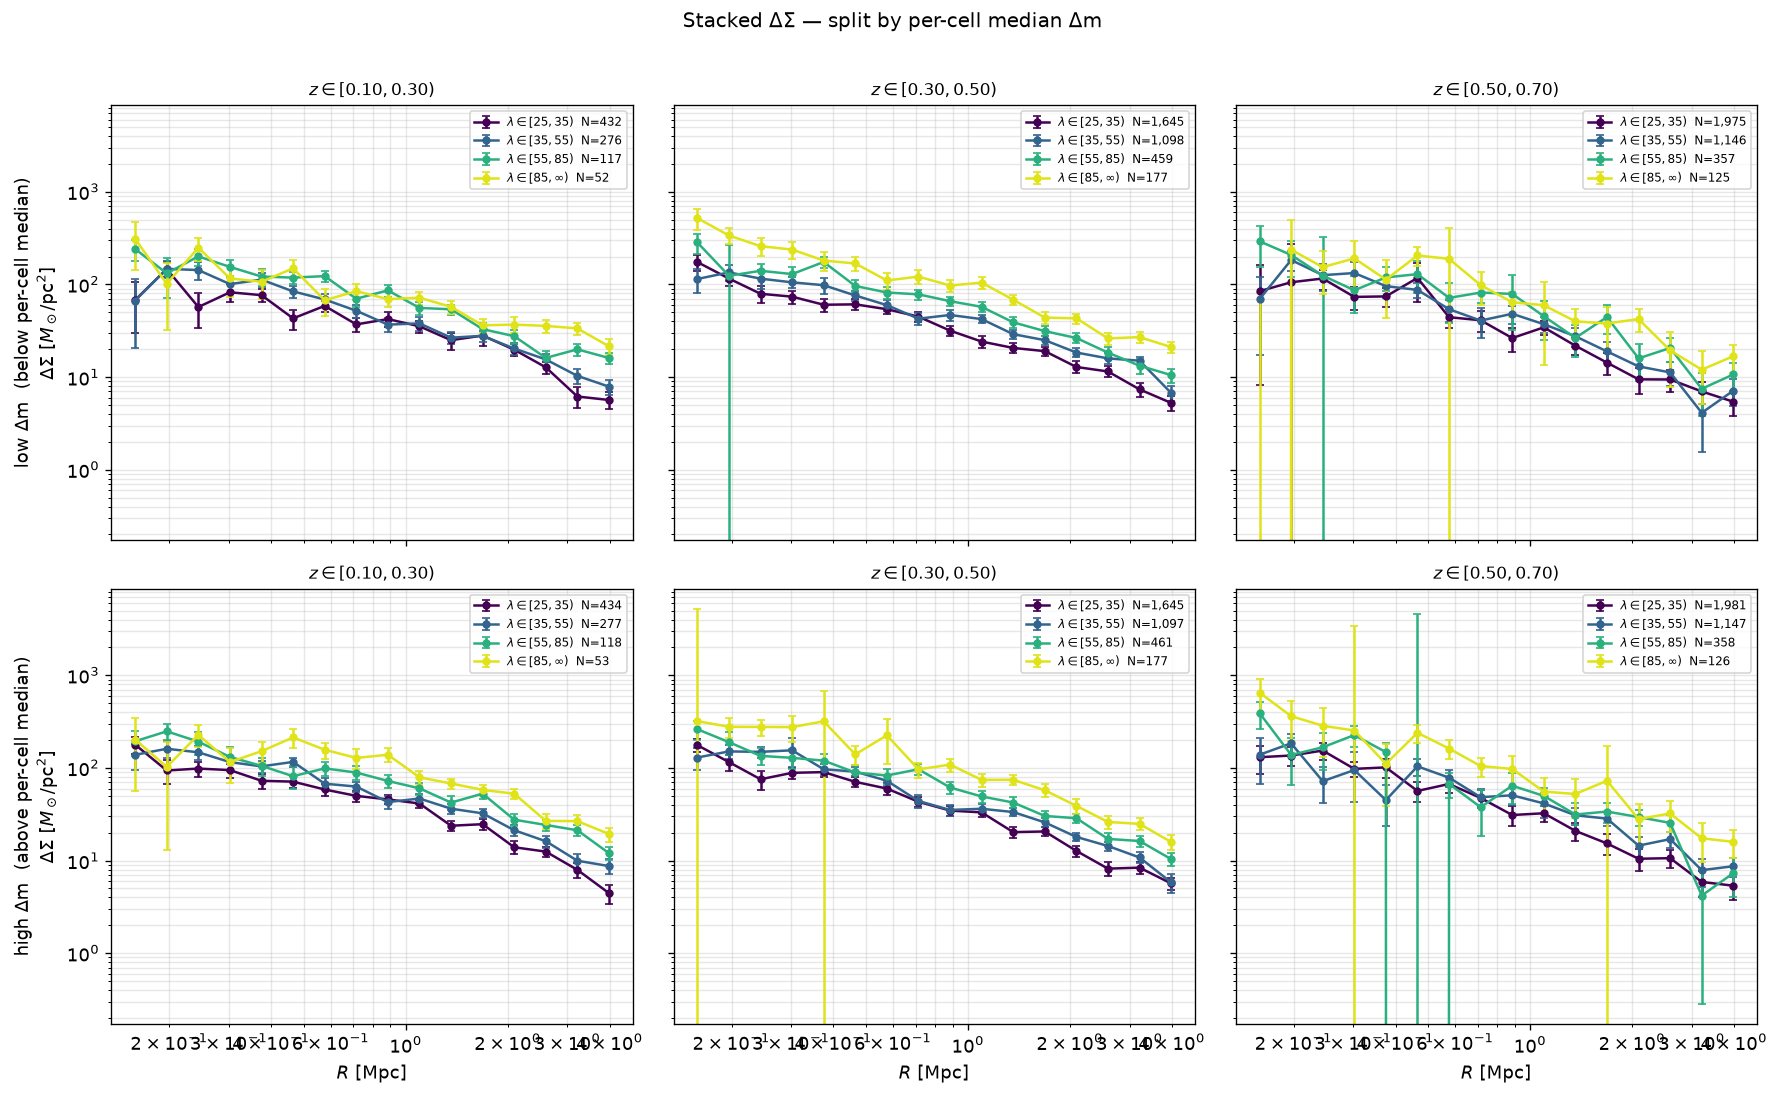

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for k in range(2):
    for i in range(3):
        ax = axes[k, i]
        for j in range(N_NG):
            name = f"z{i}_ng{j}_dm{k}"
            if name not in stacks:
                continue
            s = stacks[name]
            err = np.sqrt(np.diag(s["sigmas_cov"]))
            hi = f'{s["ng_hi"]:.0f}' if np.isfinite(s["ng_hi"]) else r"\infty"
            ax.errorbar(radii, s["sigmas"], yerr=err,
                        fmt="o-", ms=4, capsize=2.5, color=ng_colors[j],
                        label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                               f'N={s["n_stacked"]:,}'))
        ax.set_xscale("log")
        ax.set_yscale("log")
        if k == 1:
            ax.set_xlabel(r"$R$ [Mpc]")
        if i == 0:
            ax.set_ylabel(rf"{dm_titles[k]}" + "\n" + r"$\Delta\Sigma$ [$M_\odot/\mathrm{pc}^2$]")
        ax.set_title(rf"$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$", fontsize=10)
        ax.grid(alpha=0.3, which="both")
        ax.legend(fontsize=7, loc="upper right")
plt.suptitle("Stacked ΔΣ — split by per-cell median Δm", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 3 — NFW posterior corner (one example z/richness cell)

Low-Δm vs high-Δm posteriors overlaid, priors drawn on the 1D marginals.
Change `TARGET_Z`/`TARGET_NG` to inspect a different cell.

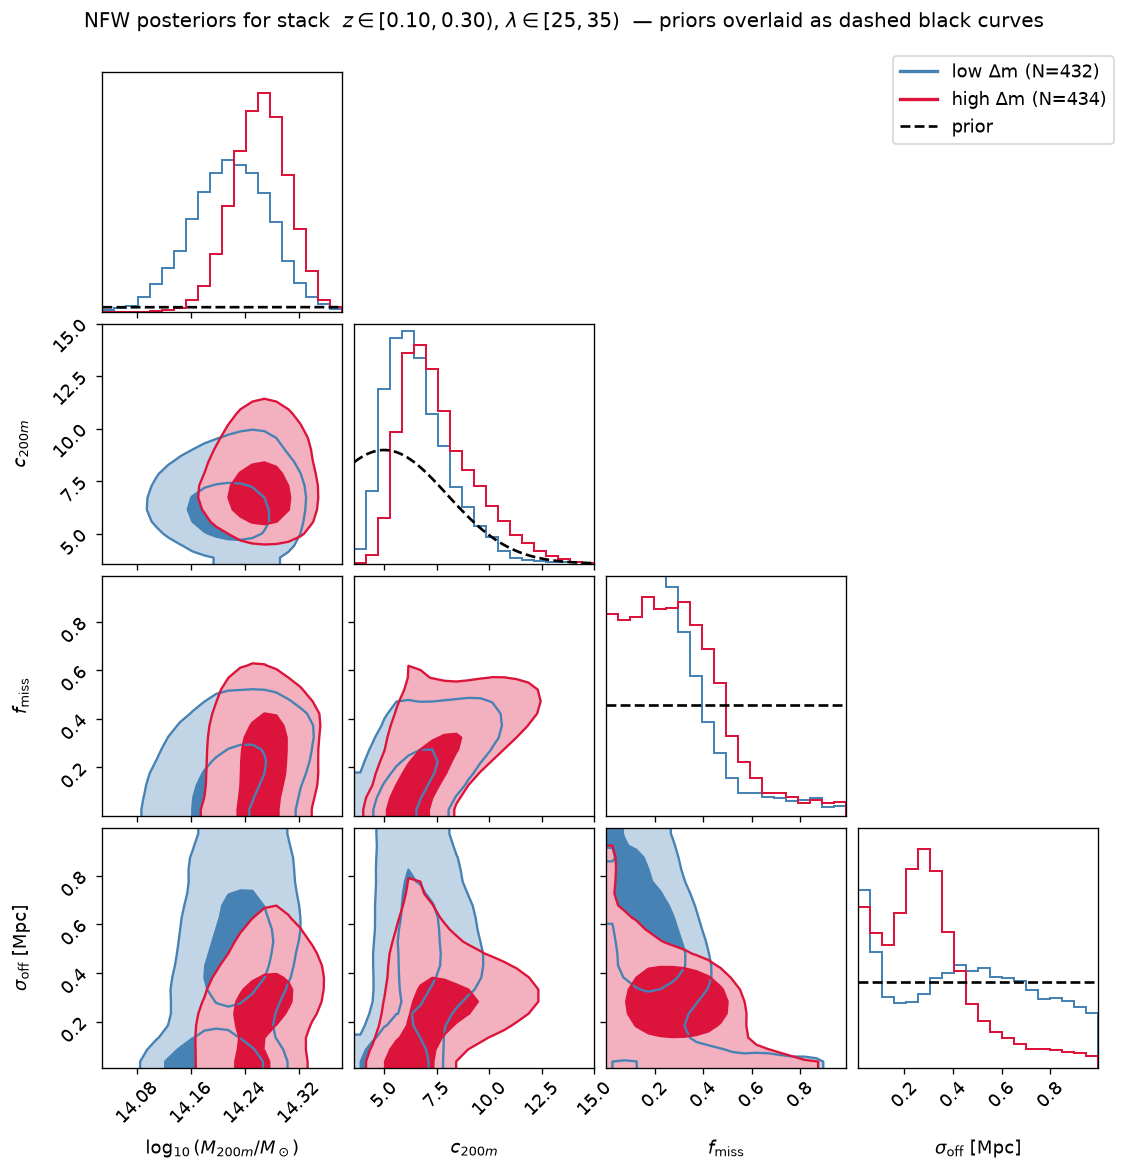

In [5]:
from scipy.stats import norm as sp_norm, truncnorm as sp_truncnorm

LOGM_MU, LOGM_SIG = 14.5, 2.0
C_MU, C_SIG = 5.0, 3.0
C_LO, C_HI = 0.1, 20.0

TARGET_Z, TARGET_NG = 0, 0
panel_names = {0: f"z{TARGET_Z}_ng{TARGET_NG}_dm0",
               1: f"z{TARGET_Z}_ng{TARGET_NG}_dm1"}
dm_corner_colors = {0: "steelblue", 1: "crimson"}
param_labels = [r"$\log_{10}(M_{200m}/M_\odot)$", r"$c_{200m}$",
                r"$f_{\rm miss}$", r"$\sigma_{\rm off}$ [Mpc]"]


def _posterior_weights(f):
    lw = np.asarray(f["log_weights"])
    w = np.exp(lw - lw.max())
    return w / w.sum()


def _weighted_quantile_range(pts_col, w, q_lo=0.001, q_hi=0.999):
    srt = np.argsort(pts_col)
    cum = np.cumsum(w[srt])
    return (float(np.interp(q_lo, cum, pts_col[srt])),
            float(np.interp(q_hi, cum, pts_col[srt])))


usable = [name for name in panel_names.values()
          if name in fits_out and not fits_out[name].get("failed")]
if len(usable) < 2:
    print(f"Need both Δm halves fitted for z{TARGET_Z}_ng{TARGET_NG}; have only {usable}")
else:
    plot_range = []
    for i in range(len(param_labels)):
        lo_hi = []
        for name in panel_names.values():
            f = fits_out[name]
            pts = np.asarray(f["samples"])
            w = _posterior_weights(f)
            lo_hi.append(_weighted_quantile_range(pts[:, i], w))
        lo = min(a for a, _ in lo_hi)
        hi = max(b for _, b in lo_hi)
        plot_range.append((lo, hi))
    plot_range[2] = (max(plot_range[2][0], 0.0), min(plot_range[2][1], 1.0))
    plot_range[3] = (max(plot_range[3][0], 0.01), min(plot_range[3][1], 1.0))

    fig = None
    for k, name in panel_names.items():
        f = fits_out[name]
        pts = np.asarray(f["samples"])
        w = _posterior_weights(f)
        ckw = dict(labels=param_labels, color=dm_corner_colors[k], weights=w,
                   range=plot_range, hist_kwargs={"density": True, "lw": 1.2},
                   plot_datapoints=False, fill_contours=True,
                   levels=(0.39, 0.86), smooth=1.0,
                   contour_kwargs={"linewidths": 1.4})
        fig = corner.corner(pts, **ckw) if fig is None else corner.corner(pts, fig=fig, **ckw)

    n = len(param_labels)
    diag_axes = [fig.axes[i * n + i] for i in range(n)]

    xs0 = np.linspace(*plot_range[0], 400)
    diag_axes[0].plot(xs0, sp_norm.pdf(xs0, loc=LOGM_MU, scale=LOGM_SIG),
                      color="black", lw=1.6, ls="--")
    xs1 = np.linspace(*plot_range[1], 400)
    diag_axes[1].plot(xs1, sp_truncnorm.pdf(
        xs1, (C_LO - C_MU) / C_SIG, (C_HI - C_MU) / C_SIG, loc=C_MU, scale=C_SIG),
        color="black", lw=1.6, ls="--")
    xs2 = np.linspace(*plot_range[2], 400)
    diag_axes[2].plot(xs2, np.where((xs2 >= 0.0) & (xs2 <= 1.0), 1.0, 0.0),
                      color="black", lw=1.6, ls="--")
    xs3 = np.linspace(*plot_range[3], 400)
    pdf3 = np.where((xs3 >= 0.01) & (xs3 <= 1.0), 1.0 / (1.0 - 0.01), 0.0)
    diag_axes[3].plot(xs3, pdf3, color="black", lw=1.6, ls="--")

    n0 = fits_out[panel_names[0]]["n_stacked"]
    n1 = fits_out[panel_names[1]]["n_stacked"]
    fig.legend(
        handles=[Line2D([0], [0], color=dm_corner_colors[0], lw=2, label=f"low Δm (N={n0:,})"),
                 Line2D([0], [0], color=dm_corner_colors[1], lw=2, label=f"high Δm (N={n1:,})"),
                 Line2D([0], [0], color="black", lw=1.6, ls="--", label="prior")],
        loc="upper right", bbox_to_anchor=(0.98, 0.98), fontsize=11, frameon=True,
    )
    s = stacks[panel_names[0]]
    hi = f'{s["ng_hi"]:.0f}' if np.isfinite(s["ng_hi"]) else r"\infty"
    fig.suptitle(
        rf'NFW posteriors for stack  $z\in[{s["z_lo"]:.2f},{s["z_hi"]:.2f})$, '
        rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  — priors overlaid as dashed black curves',
        fontsize=12, y=1.01,
    )
    plt.show()

## 4 — Mass–richness data + best-fit power laws

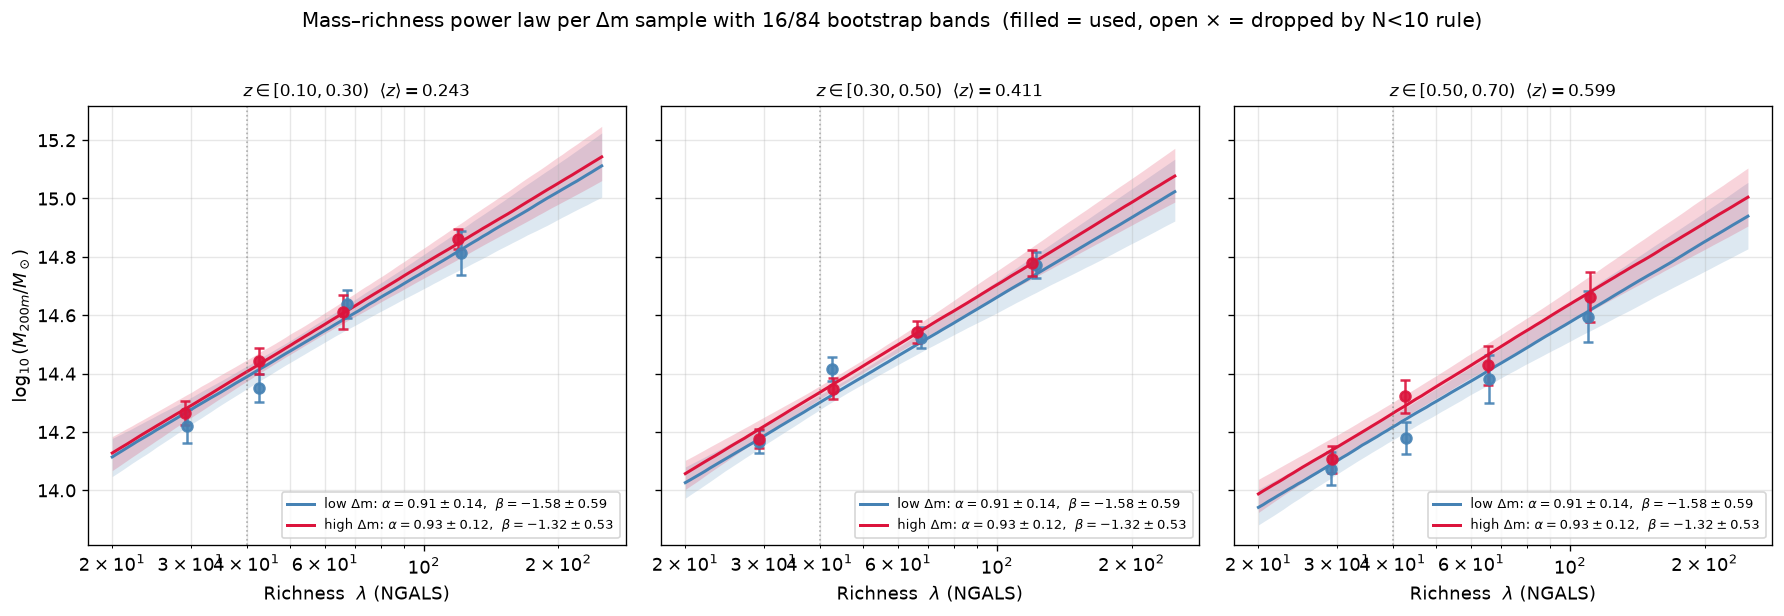

In [6]:
dm_colors = {0: "steelblue", 1: "crimson"}
dm_labels = {0: "low Δm", 1: "high Δm"}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
lam_smooth = np.geomspace(20, 250, 100)
x_lam = np.log10(lam_smooth / LAM_PIV)

for i in range(3):
    ax = axes[i]
    z_in_slice = [f["z_mean"] for n, f in fits_out.items()
                  if int(n.split("_")[0][1:]) == i and not f.get("failed")]
    z_slice_mean = (float(np.mean(z_in_slice)) if z_in_slice
                    else 0.5 * (z_edges[i] + z_edges[i + 1]))
    z_term = np.log10((1.0 + z_slice_mean) / (1.0 + Z_PIV))

    for k in (0, 1):
        for name, f in fits_out.items():
            if int(name.split("_")[0][1:]) != i or f.get("dm_bin") != k or f.get("failed"):
                continue
            lam_pt = f["lambda_mean"]
            logM_pt = f["mean"]["log_M"]
            sig_pt = 0.5 * (f["quantiles"]["log_M"][1] - f["quantiles"]["log_M"][0])
            n_clust = f["n_stacked"]
            used = n_clust >= MIN_N_FOR_FIT
            ax.errorbar(lam_pt, logM_pt, yerr=sig_pt,
                        fmt="o" if used else "x", ms=6 if used else 9,
                        mew=1.5 if used else 2, color=dm_colors[k],
                        markerfacecolor=dm_colors[k] if used else "none",
                        capsize=3, alpha=0.9 if used else 0.6)
        if k in ml_fits:
            samples_k = np.asarray(ml_fits[k]["samples"], dtype=float)
            samples_k = samples_k[np.all(np.isfinite(samples_k), axis=1)]
            logM_lines = (samples_k[:, 2:3] + samples_k[:, 0:1] * x_lam[None, :]
                         + samples_k[:, 1:2] * z_term)
            band_lo = np.percentile(logM_lines, 16, axis=0)
            band_hi = np.percentile(logM_lines, 84, axis=0)
            band_med = np.median(logM_lines, axis=0)
            ax.fill_between(lam_smooth, band_lo, band_hi, color=dm_colors[k], alpha=0.18, lw=0)
            m, s = ml_fits[k]["mean"], ml_fits[k]["sigma"]
            ax.plot(lam_smooth, band_med, "-", color=dm_colors[k], lw=1.8,
                    label=(rf'{dm_labels[k]}: $\alpha={m["alpha"]:.2f}\pm{s[0]:.2f}$,  '
                           rf'$\beta={m["beta"]:.2f}\pm{s[1]:.2f}$'))
    ax.axvline(LAM_PIV, color="grey", ls=":", lw=1.0, alpha=0.6)
    ax.set_xscale("log")
    ax.set_xlabel(r"Richness  $\lambda$ (NGALS)")
    if i == 0:
        ax.set_ylabel(r"$\log_{10}(M_{200m}/M_\odot)$")
    ax.set_title(rf"$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$  "
                 rf"$\langle z\rangle={z_slice_mean:.3f}$", fontsize=10)
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8, loc="lower right")

plt.suptitle(rf"Mass–richness power law per Δm sample with 16/84 bootstrap bands  "
             rf"(filled = used, open × = dropped by N<{MIN_N_FOR_FIT} rule)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 5 — Mass–richness contour: $(\alpha, \beta, \log M_0)$ by Δm group

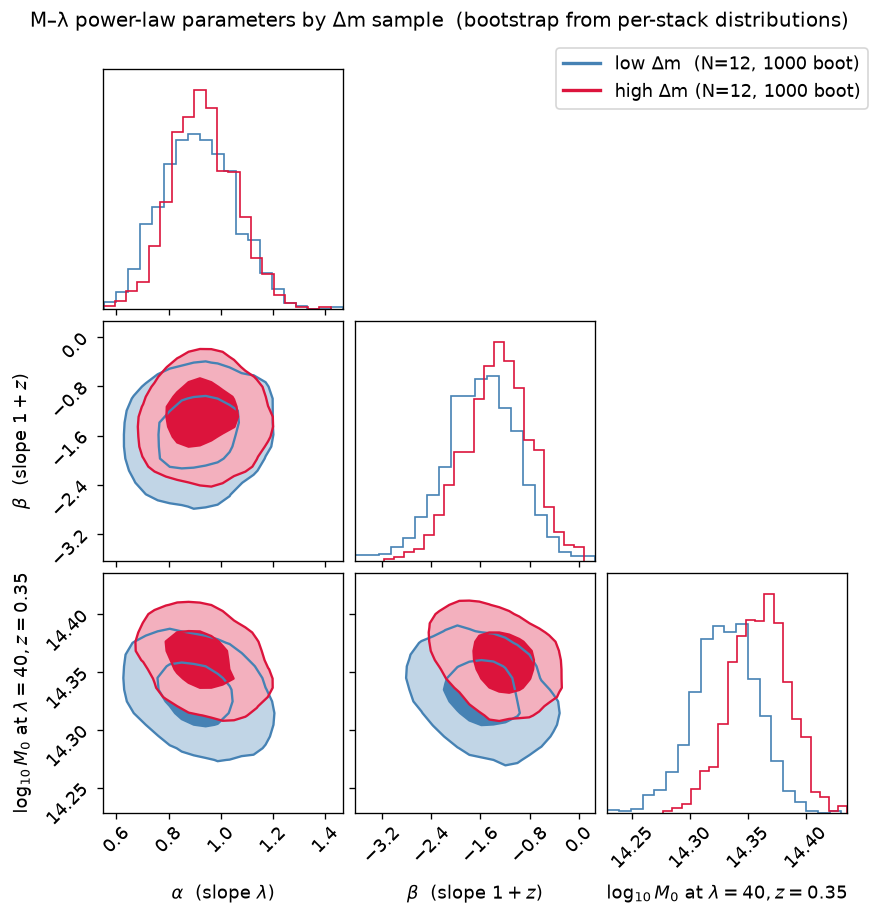


  Δ alpha (high - low) = +0.020 ± 0.184   (+0.11 sigma)
  Δ  beta (high - low) = +0.255 ± 0.794   (+0.32 sigma)
  Δ logM0 (high - low) = +0.029 ± 0.037   (+0.80 sigma)


In [7]:
param_names = ["alpha", "beta", "logM0"]
labels = [r"$\alpha$  (slope $\lambda$)", r"$\beta$  (slope $1+z$)",
          rf"$\log_{{10}} M_0$ at $\lambda={LAM_PIV:.0f}, z={Z_PIV:.2f}$"]

if 0 in ml_fits and 1 in ml_fits:
    samples_low = np.asarray(ml_fits[0]["samples"], dtype=float)
    samples_high = np.asarray(ml_fits[1]["samples"], dtype=float)
    samples_low = samples_low[np.all(np.isfinite(samples_low), axis=1)]
    samples_high = samples_high[np.all(np.isfinite(samples_high), axis=1)]

    fig = corner.corner(samples_low, labels=labels, color="steelblue",
                        hist_kwargs={"density": True}, plot_datapoints=False,
                        fill_contours=True, levels=(0.39, 0.86), smooth=1.0,
                        contour_kwargs={"linewidths": 1.4})
    corner.corner(samples_high, color="crimson", hist_kwargs={"density": True},
                 plot_datapoints=False, fill_contours=True, levels=(0.39, 0.86),
                 smooth=1.0, contour_kwargs={"linewidths": 1.4}, fig=fig)
    fig.legend(
        handles=[Line2D([0], [0], color="steelblue", lw=2,
                        label=f'low Δm  (N={ml_fits[0]["n_stacks"]}, {len(samples_low)} boot)'),
                 Line2D([0], [0], color="crimson", lw=2,
                        label=f'high Δm (N={ml_fits[1]["n_stacks"]}, {len(samples_high)} boot)')],
        loc="upper right", bbox_to_anchor=(0.98, 0.98), fontsize=11, frameon=True,
    )
    fig.suptitle("M–λ power-law parameters by Δm sample  "
                 "(bootstrap from per-stack distributions)", fontsize=12, y=1.01)
    plt.show()

    print()
    for p in param_names:
        m0, m1 = ml_fits[0]["mean"][p], ml_fits[1]["mean"][p]
        s0 = ml_fits[0]["sigma"][param_names.index(p)]
        s1 = ml_fits[1]["sigma"][param_names.index(p)]
        diff = m1 - m0
        sigma_diff = np.sqrt(s0 ** 2 + s1 ** 2)
        print(f"  Δ{p:>6} (high - low) = {diff:+.3f} ± {sigma_diff:.3f}   "
              f"({diff / sigma_diff:+.2f} sigma)")
else:
    print("Need both Δm groups fitted to draw the contour comparison.")

## 6 — Mass–concentration data + best-fit power laws, with theoretical overlays

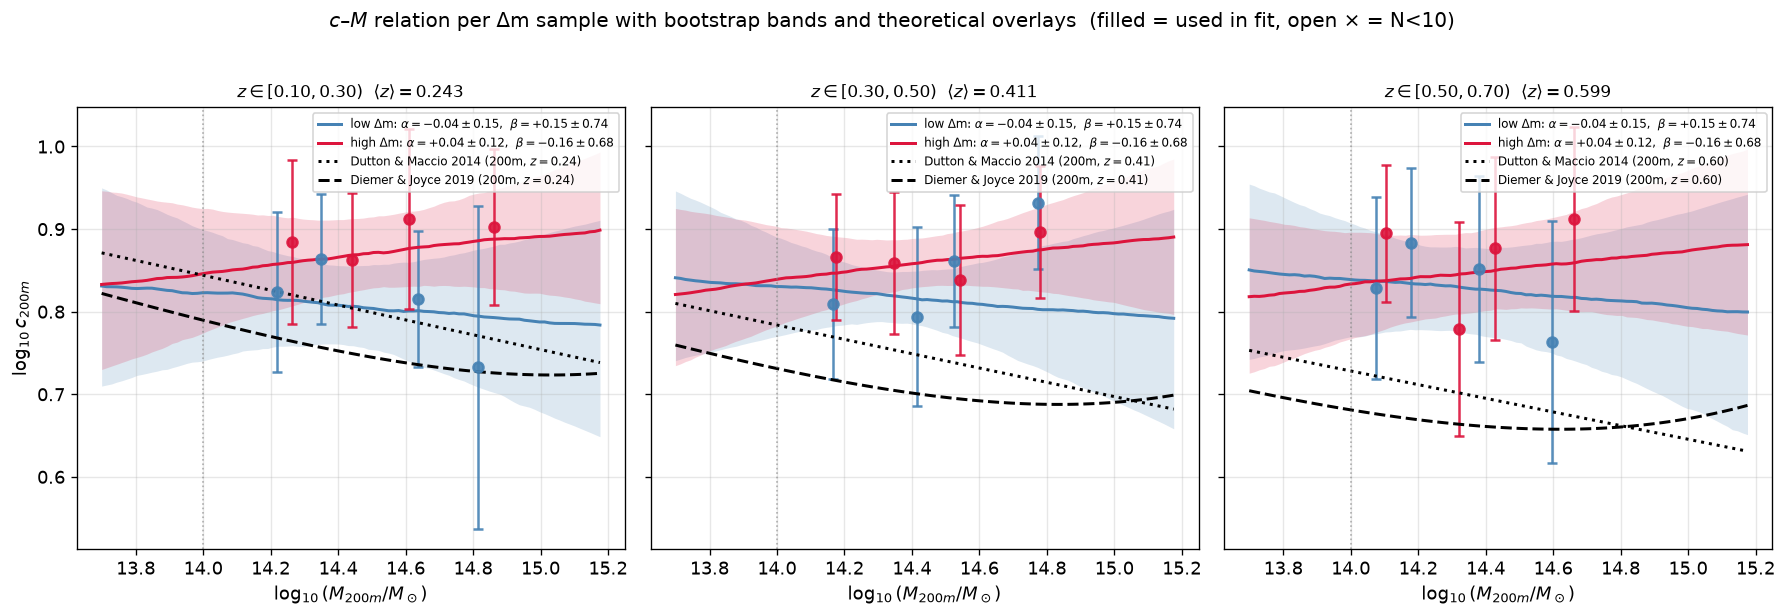

In [8]:
from colossus.cosmology import cosmology as colossus_cosmo
from colossus.halo import concentration as colossus_conc

colossus_cosmo.setCosmology("planck18")
HH = float(colossus_cosmo.getCurrent().h)

CMR_MODELS = ["dutton14", "diemer19"]
CMR_MDEF = "200m"
CMR_STYLES = {
    "dutton14": (":", "Dutton & Maccio 2014"),
    "diemer19": ("--", "Diemer & Joyce 2019"),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
M_smooth = np.geomspace(0.5e14, 1.5e15, 100)
logM_smooth = np.log10(M_smooth)
x_m = logM_smooth - np.log10(CMR_M_PIV)

for i in range(3):
    ax = axes[i]
    z_in_slice = [f["z_mean"] for n, f in fits_out.items()
                  if int(n.split("_")[0][1:]) == i and not f.get("failed")]
    z_slice_mean = (float(np.mean(z_in_slice)) if z_in_slice
                    else 0.5 * (z_edges[i] + z_edges[i + 1]))
    z_term = np.log10((1.0 + z_slice_mean) / (1.0 + CMR_Z_PIV))

    for k in (0, 1):
        for name, f in fits_out.items():
            if int(name.split("_")[0][1:]) != i or f.get("dm_bin") != k or f.get("failed"):
                continue
            C_mean = f["mean"]["C"]
            C_lo, C_hi = f["quantiles"]["C"]
            if C_mean <= 0 or C_lo <= 0 or C_hi <= 0:
                continue
            logC = np.log10(C_mean)
            sig = 0.5 * (np.log10(C_hi) - np.log10(C_lo))
            logM_pt = f["mean"]["log_M"]
            n_clust = f["n_stacked"]
            used = n_clust >= MIN_N_FOR_FIT
            ax.errorbar(logM_pt, logC, yerr=sig,
                        fmt="o" if used else "x", ms=6 if used else 9,
                        mew=1.5 if used else 2, color=dm_colors[k],
                        markerfacecolor=dm_colors[k] if used else "none",
                        capsize=3, alpha=0.9 if used else 0.6)
        if k in cmr_fits:
            samples_k = np.asarray(cmr_fits[k]["samples"], dtype=float)
            samples_k = samples_k[np.all(np.isfinite(samples_k), axis=1)]
            logC_lines = (samples_k[:, 2:3] + samples_k[:, 0:1] * x_m[None, :]
                         + samples_k[:, 1:2] * z_term)
            band_lo = np.percentile(logC_lines, 16, axis=0)
            band_hi = np.percentile(logC_lines, 84, axis=0)
            band_med = np.median(logC_lines, axis=0)
            ax.fill_between(logM_smooth, band_lo, band_hi, color=dm_colors[k], alpha=0.18, lw=0)
            m, s = cmr_fits[k]["mean"], cmr_fits[k]["sigma"]
            ax.plot(logM_smooth, band_med, "-", color=dm_colors[k], lw=1.8,
                    label=(rf'{dm_labels[k]}: $\alpha={m["alpha"]:+.2f}\pm{s[0]:.2f}$,  '
                           rf'$\beta={m["beta"]:+.2f}\pm{s[1]:.2f}$'))

    for model in CMR_MODELS:
        ls, pretty = CMR_STYLES.get(model, ("--", model))
        c_col = colossus_conc.concentration(M=M_smooth * HH, mdef=CMR_MDEF,
                                            z=z_slice_mean, model=model)
        ax.plot(logM_smooth, np.log10(c_col), linestyle=ls, color="black", lw=1.8,
                label=rf"{pretty} ({CMR_MDEF}, $z={z_slice_mean:.2f}$)")

    ax.axvline(np.log10(CMR_M_PIV), color="grey", ls=":", lw=1.0, alpha=0.6)
    ax.set_xlabel(r"$\log_{10}(M_{200m}/M_\odot)$")
    if i == 0:
        ax.set_ylabel(r"$\log_{10} c_{200m}$")
    ax.set_title(rf"$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$  "
                 rf"$\langle z\rangle={z_slice_mean:.3f}$", fontsize=10)
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=7, loc="upper right")

plt.suptitle(rf"$c$–$M$ relation per Δm sample with bootstrap bands and theoretical overlays  "
             rf"(filled = used in fit, open × = N<{MIN_N_FOR_FIT})", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

## 7 — Mass–concentration contour: $(\alpha, \beta, \log c_0)$ by Δm group

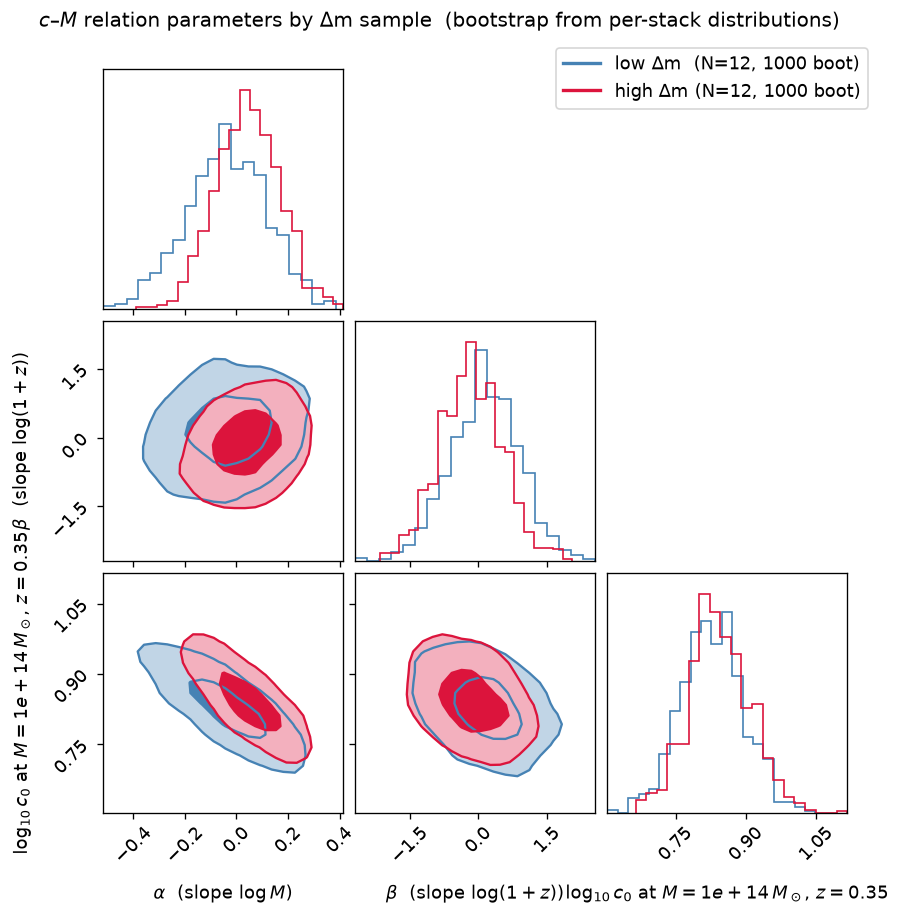


  Δ alpha (high - low) = +0.081 ± 0.196   (+0.41 sigma)
  Δ  beta (high - low) = -0.309 ± 1.009   (-0.31 sigma)
  Δ logC0 (high - low) = +0.016 ± 0.093   (+0.17 sigma)


In [9]:
param_names = ["alpha", "beta", "logC0"]
labels = [r"$\alpha$  (slope $\log M$)", r"$\beta$  (slope $\log(1+z)$)",
          rf"$\log_{{10}} c_0$ at $M={CMR_M_PIV:.0e}\,M_\odot$, $z={CMR_Z_PIV:.2f}$"]

if 0 in cmr_fits and 1 in cmr_fits:
    samples_low = np.asarray(cmr_fits[0]["samples"], dtype=float)
    samples_high = np.asarray(cmr_fits[1]["samples"], dtype=float)
    samples_low = samples_low[np.all(np.isfinite(samples_low), axis=1)]
    samples_high = samples_high[np.all(np.isfinite(samples_high), axis=1)]

    fig = corner.corner(samples_low, labels=labels, color="steelblue",
                        hist_kwargs={"density": True}, plot_datapoints=False,
                        fill_contours=True, levels=(0.39, 0.86), smooth=1.0,
                        contour_kwargs={"linewidths": 1.4})
    corner.corner(samples_high, color="crimson", hist_kwargs={"density": True},
                 plot_datapoints=False, fill_contours=True, levels=(0.39, 0.86),
                 smooth=1.0, contour_kwargs={"linewidths": 1.4}, fig=fig)
    fig.legend(
        handles=[Line2D([0], [0], color="steelblue", lw=2,
                        label=f'low Δm  (N={cmr_fits[0]["n_stacks"]}, {len(samples_low)} boot)'),
                 Line2D([0], [0], color="crimson", lw=2,
                        label=f'high Δm (N={cmr_fits[1]["n_stacks"]}, {len(samples_high)} boot)')],
        loc="upper right", bbox_to_anchor=(0.98, 0.98), fontsize=11, frameon=True,
    )
    fig.suptitle("$c$–$M$ relation parameters by Δm sample  "
                 "(bootstrap from per-stack distributions)", fontsize=12, y=1.01)
    plt.show()

    print()
    for p in param_names:
        m0, m1 = cmr_fits[0]["mean"][p], cmr_fits[1]["mean"][p]
        s0 = cmr_fits[0]["sigma"][param_names.index(p)]
        s1 = cmr_fits[1]["sigma"][param_names.index(p)]
        diff = m1 - m0
        sigma_diff = np.sqrt(s0 ** 2 + s1 ** 2)
        print(f"  Δ{p:>6} (high - low) = {diff:+.3f} ± {sigma_diff:.3f}   "
              f"({diff / sigma_diff:+.2f} sigma)")
else:
    print("Need both Δm groups fitted to draw the contour comparison.")